# Projeto Comercial - Google Colab

## EQUIPE
1- Carlos Eduardo Moreira dos Santos

### Análise de Dados de Vendas, Clientes e Produtos
---
**Objetivo:** Aplicar técnicas de análise de dados em um cenário comercial.
Use Pandas, Numpy e Matplotlib para responder às questões propostas.

## 1. Importação de Bibliotecas

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# *** Parte 1 — Leitura e Preparação dos Dados


## 1.1. Leitura dos Arquivos CSV

In [2]:
vendas = pd.read_csv('vendas.csv')
clientes = pd.read_csv('clientes.csv')
produtos = pd.read_csv('produtos.csv')

## 1.2. Integração e Limpeza dos Dados

In [3]:
df_parcial = pd.merge(vendas, clientes, on='id_cliente', how='left')
df = pd.merge(df_parcial, produtos, on='id_produto', how='left')

In [4]:
df['valor_total'] = df['quantidade'] * df['preco_unitario'] * (1-df['desconto'])
df['valor_total'] = df['valor_total'].round(2)
df.head()

,id_venda,id_cliente,id_produto,data_venda,quantidade,desconto,nome_cliente,cidade,estado,segmento,nome_produto,categoria,preco_unitario,valor_total
0,1,1,101,2024-01-15,3,0.05,Ana Souza,São Paulo,SP,Varejo,Caderno Universitário,Papelaria,25.9,73.81
1,2,2,103,2024-02-02,1,0.10,João Lima,Rio de Janeiro,RJ,Atacado,Mochila Escolar,Acessórios,120.0,108.00
2,3,3,102,2024-02-10,10,0.00,Carla Nunes,Belo Horizonte,MG,Varejo,Caneta Azul,Papelaria,2.5,25.00
3,4,4,104,2024-03-05,2,0.15,Marcos Dias,Curitiba,PR,Atacado,Calculadora Científica,Eletrônicos,89.9,152.83
4,5,5,101,2024-03-12,5,0.05,Paula Torres,Salvador,BA,Varejo,Caderno Universitário,Papelaria,25.9,123.02


## *** Parte 2 — Análise Exploratória

## 2.1- BÁSICA


In [11]:
#Total de vendas por mês
df['data_venda'] = pd.to_datetime(df['data_venda'])
df['mes'] = df['data_venda'].dt.strftime('%m')

vendas_mes = df.groupby('mes').agg(
    valor_total_mes = ('valor_total', 'sum'),
    total_produtos_vendidos = ('quantidade', 'sum'),
    numero_de_pedidos = ('id_venda', 'count')
).reset_index()

#Total de vendas por estado e segmento
vendas_estado = df.groupby(['estado','segmento']).agg(
     valor_total_estado = ('valor_total', 'sum'),
     total_produtos_vendidos = ('quantidade', 'sum'),
     numero_de_pedidos = ('id_venda', 'count')
).reset_index()

#Produto mais vendidos por valor
mais_vendido_valor = df.groupby('nome_produto')['valor_total'].sum().sort_values(ascending=False)
produto_nome = mais_vendido_valor.idxmax()
produto_valor = mais_vendido_valor.max()
print(f"O produto mais vendido em valor foi: {produto_nome}. Ele vendeu: R$ {produto_valor}")

#Produto mais vendidos por quantidade
mais_vendido_quantidade = df.groupby('nome_produto')['quantidade'].sum().sort_values(ascending=False)
produto_nome_quantidade = mais_vendido_quantidade.idxmax()
produto_quantidade = mais_vendido_quantidade.max()
print(f"O produto mais vendido em quantidade foi: {produto_nome_quantidade}. Ele vendeu: {produto_quantidade} unidades!")

#Cliente com o maior volume de compras
cliente_maior = df.groupby('nome_cliente')['valor_total'].sum().sort_values(ascending=False)
maior_comprador_nome = cliente_maior.idxmax()
maior_comprador_valor = cliente_maior.max()
print(f"\nO cliente que mais comprou foi: {maior_comprador_nome}; Que comprou um total de R$ {maior_comprador_valor}")

#Receita total e média de descontos aplicados
receita_total = df['valor_total'].sum()
print(f"\nReceita total: R$ {receita_total}")

df['valor_total_desconto'] = df['quantidade'] * df['preco_unitario'] * df['desconto']
df['valor_total_desconto'] = df['valor_total_desconto'].round(2)
media_desconto = df['valor_total_desconto'].mean().round(2)
print(f"O valor médio do desconto foi de R${media_desconto}")

O produto mais vendido em valor foi: Mochila Escolar. Ele vendeu: R$ 8448.0
O produto mais vendido em quantidade foi: Mochila Escolar. Ele vendeu: 75 unidades!

O cliente que mais comprou foi: Rodrigo Costa. Que comprou um total de R$ 2961.0

Receita total: R$ 22647.74
O valor médio do desconto foi de R$24.1


## 2.2- AVANÇADA

In [9]:
#Criar um ranking de produtos mais rentáveis
produtos_mais_rentaveis = df.groupby(['id_produto', 'nome_produto', 'categoria']).agg(
    valor_total = ('valor_total', 'sum'),
    unidades_vendidas = ('quantidade', 'sum'),
    numero_de_pedidos = ('id_venda', 'count')
).reset_index()
produtos_mais_rentaveis = produtos_mais_rentaveis.sort_values('valor_total', ascending = False).reset_index(drop = True)

#Calcular ticket médio por cliente
ticket_medio_cliente = df.groupby(['id_cliente', 'nome_cliente']).agg(
    valor_total_comprado = ('valor_total', 'sum'),
    numero_de_pedidos = ('id_venda', 'count')
).reset_index()
ticket_medio_cliente['ticket_medio'] = ticket_medio_cliente['valor_total_comprado'] / ticket_medio_cliente['numero_de_pedidos']
ticket_medio_cliente['ticket_medio'] = ticket_medio_cliente['ticket_medio'].round(2)
ticket_medio_geral = ticket_medio_cliente['ticket_medio'].mean().round(2)
print(f"\nO ticket médio por cliente foi de: R${ticket_medio_geral}.")

#Simular um cenário com aumento de preços de 10% e recalcular receitas
df['preco_unitario_aumentado'] = df['preco_unitario'] * 1.1
df['valor_total_simulado'] = df['quantidade'] * df['preco_unitario_aumentado'] * (1-df['desconto'])
df['valor_total_simulado'] = df['valor_total_simulado'].round(2)
faturamento_atual = df['valor_total'].sum()
faturamento_simulado = df['valor_total_simulado'].sum()
df.head()


O ticket médio por cliente foi de: R$209.73.


,id_venda,id_cliente,id_produto,data_venda,quantidade,desconto,nome_cliente,cidade,estado,segmento,nome_produto,categoria,preco_unitario,valor_total,mes,valor_total_desconto,preco_unitario_aumentado,valor_total_simulado
0,1,1,101,2024-01-15,3,0.05,Ana Souza,São Paulo,SP,Varejo,Caderno Universitário,Papelaria,25.9,73.81,01,3.88,28.49,81.20
1,2,2,103,2024-02-02,1,0.10,João Lima,Rio de Janeiro,RJ,Atacado,Mochila Escolar,Acessórios,120.0,108.00,02,12.00,132.00,118.80
2,3,3,102,2024-02-10,10,0.00,Carla Nunes,Belo Horizonte,MG,Varejo,Caneta Azul,Papelaria,2.5,25.00,02,0.00,2.75,27.50
3,4,4,104,2024-03-05,2,0.15,Marcos Dias,Curitiba,PR,Atacado,Calculadora Científica,Eletrônicos,89.9,152.83,03,26.97,98.89,168.11
4,5,5,101,2024-03-12,5,0.05,Paula Torres,Salvador,BA,Varejo,Caderno Universitário,Papelaria,25.9,123.02,03,6.48,28.49,135.33


2.3- Análise criada pela Equipe

In [ ]:
df.to_excel('relatorio_vendas.xlsx', index = False)

## *** Parte 3 — Análise E Visualizações Gráficas

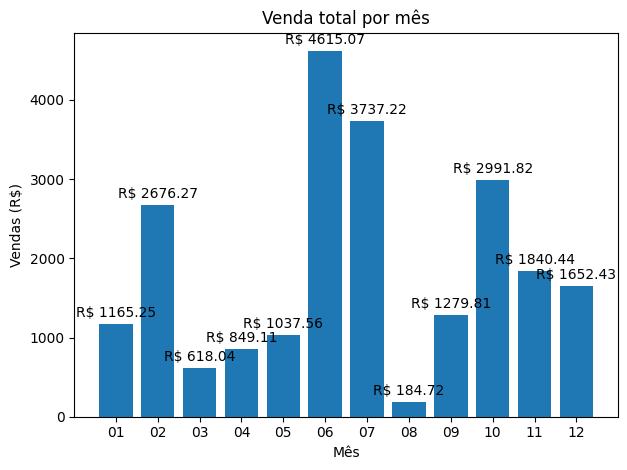

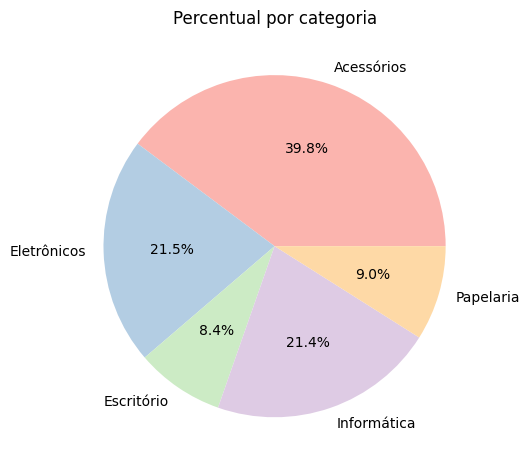

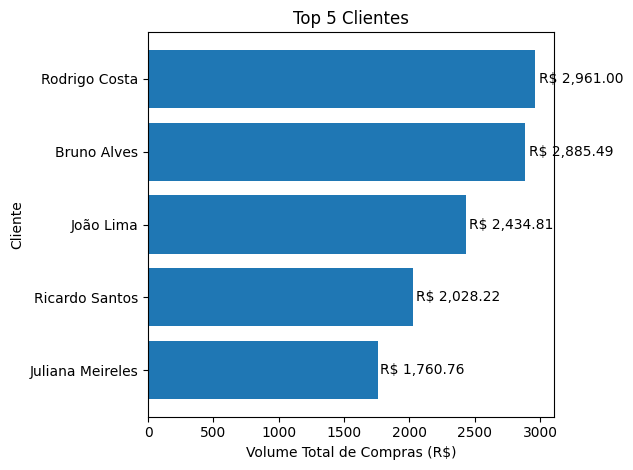

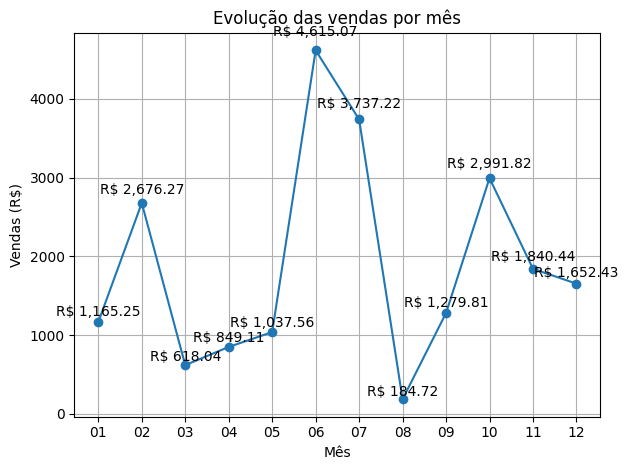

In [12]:
#Gráfico de barras: total de vendas por mês.
barras = plt.bar(
    vendas_mes['mes'],
    vendas_mes['valor_total_mes']
)
for barra in barras:
    altura = barra.get_height()

    plt.text(
        barra.get_x() + barra.get_width() / 2,
        altura + 50,
        f"R$ {altura:.2f}",
        ha='center',
        va='bottom',
    )
plt.title ('Venda total por mês')
plt.xlabel ('Mês')
plt.ylabel ('Vendas (R$)')
plt.tight_layout()
plt.savefig('grafico_barras_vendas_mes.png')
plt.show()

#Gráfico de pizza: percentual de vendas por categoria de produto
vendas_categoria = df.groupby('categoria').agg(
    valor_total_cat = ('valor_total', 'sum'),
    total_produtos_vendidos = ('quantidade', 'sum'),
    numero_de_pedidos = ('id_venda', 'count')
).reset_index()

plt.pie(
    vendas_categoria['valor_total_cat'],
    labels=vendas_categoria['categoria'],
    autopct='%1.1f%%',
    colors=plt.cm.Pastel1.colors
)
plt.title ('Percentual por categoria')
plt.tight_layout()
plt.savefig('grafico_pizza_categorias')
plt.show()

#Gráfico de barras horizontais: top 5 clientes
top_clientes = cliente_maior.head(5)[::-1]

barras = plt.barh(
    top_clientes.index,
    top_clientes.values,
)
for barra in barras:
    largura = barra.get_width()
    plt.text(
        largura + (largura * 0.01),
        barra.get_y() + barra.get_height() / 2,
        f"R$ {largura:,.2f}",
        ha='left', va='center',
    )
plt.title ('Top 5 Clientes')
plt.xlabel ('Volume Total de Compras (R$)')
plt.ylabel ('Cliente')
plt.tight_layout()
plt.savefig('grafico_barrash_top_clientes.png')
plt.show()

#Gráfico de linha: evolução da receita mensal
plt.plot(
    vendas_mes['mes'],
    vendas_mes['valor_total_mes'],
    marker = 'o',
)
for x, y in zip(vendas_mes['mes'], vendas_mes['valor_total_mes']):
    plt.text(
        x,
        y * 1.03,
        f"R$ {y:,.2f}",
        ha='center',
        va='bottom',
    )
plt.grid(True)
plt.title ('Evolução das vendas por mês')
plt.xlabel ('Mês')
plt.ylabel ('Vendas (R$)')
plt.tight_layout()
plt.savefig('grafico_linha_evolucao_mensal.png')
plt.show()

## 4. Conclusões e Insights
Analisando os dados informados nos arquivos 'csv' e os dados colhidos a partir da sua junção e dissecação, podemos chamar a atenção para alguns pontos relevantes:

1 - O produto mais vendido: Entre as 20 opções no catálogo da loja, é interessante notar que o item Mochila Escolar foi o mais vendido tanto em valor total quanto em unidades vendidas. O item, sozinho, foi responsável por quase 40% do faturamento total, isso mostra uma alta demanda e potencial para cresimento futuro. Nesse aspecto, uma boa opção seria diversificar ainda mais a variedade de produtos, tanto em tamanho/ estética, quanto em faixas de preço. Isso aumentaria o alcance entre os consumidores e as possibilidades de vendas em cenários diversos.

2 - A evolução do faturamento mensal mostra uma alta vertiginosa em determidados meses, seguida por queda brusca em outros momentos (especialmente no miolo do primeiro e segundo semestre). Ao mesmo tempo, nota-se que após o pedíodo de maior alta nas vendas (meses 6 e 7), vem o momento de maior baixa (mês 8) o que indica um potencial desperdiçado de conversão. É importante manter o fluxo de vendas o mais próximo possível e fazer uma identificação de produtos mais recorrentes nas necessidades dos clientes, para que eles voltem constantemente e continuem comprando corriqueiramente.

3 - Depois da categoria 'Acessórios' (puxada pelo item Mochila Escolar), as categorias que melhor performam são 'Informática' e 'Eletrônicos'. Explorar o potencial comercial delas é um caminho interessante para aumentar faturamento e captação de clientes. Historicamente, produtos dessas categorias tendem a representar parte importante do consumo das pessoas, além de terem valor agregado e margens interessantes para o comerciante.

4 - Por fim, é bom ressaltar que o ticket médio da empresa (cerca de R$210) deve ser um ponto de atenção para a sequência da operação. Para aumentar esse valor, precisa ser feita uma ampla campanha de mobilização para vendas no atacado, que acabam por representar um lucro operacional e uma margem um pouco menor, mas aumentam exponencialmente o ticket e o fluxo de mercadorias, fazendo o capital girar e serem abertas possibilidades de expansão do portfólio e das operações.